# 02 - LLM Feature Engineering & EDA

**Author:** Member 2 (Adam Harith) | **Date:** 24 Nov 2026

**Contents:**
1. Data loading & quality checks
2. Exploratory Data Analysis (EDA)
3. LLM/SLM feature extraction from `customer_feedback`
4. Shared preprocessing pipeline

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG_DIR = "../figures/"

df = pd.read_csv("../data/processed/loan_data.csv")
print(df.shape)
df.head()

(1200, 13)


,customer_id,age,annual_income,loan_amount,loan_term_months,credit_score,existing_debts,employment_years,employment_type,region,loan_purpose,customer_feedback,default
0,C0001,24,53500,46500,84,790,93200,0,Salaried,Penang,Personal,"Things are okay, just a bit stretched compared...",0
1,C0002,38,53000,81500,72,711,132700,5,Contract,Klang Valley,Car,Every ringgit is already spoken for by the tim...,1
2,C0003,49,63500,75000,84,504,27900,18,Salaried,Klang Valley,Car,I've asked family for small help once or twice...,0
3,C0004,65,147000,109000,60,547,79400,7,Contract,Sarawak,Car,"I'm begging for some flexibility on the RM2,36...",1
4,C0005,21,54500,56500,72,693,35800,0,Contract,Klang Valley,Education,I'd call my situation tight but under control....,0


## 1. Data Quality Checks

In [14]:
print("Data types:\n", df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate customer_id:", df["customer_id"].duplicated().sum())
print("Duplicate feedback text:", df["customer_feedback"].duplicated().sum())

Data types:
 customer_id            str
age                  int64
annual_income        int64
loan_amount          int64
loan_term_months     int64
credit_score         int64
existing_debts       int64
employment_years     int64
employment_type        str
region                 str
loan_purpose           str
customer_feedback      str
default              int64
dtype: object 

Missing values per column:
 customer_id          0
age                  0
annual_income        0
loan_amount          0
loan_term_months     0
credit_score         0
existing_debts       0
employment_years     0
employment_type      0
region               0
loan_purpose         0
customer_feedback    0
default              0
dtype: int64 

Duplicate customer_id: 0
Duplicate feedback text: 0


In [15]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,1200.0,43.2,13.1,21.0,32.0,43.0,55.0,65.0
annual_income,1200.0,76898.8,44308.2,24000.0,45000.0,66000.0,95625.0,300000.0
loan_amount,1200.0,119106.7,120822.0,5000.0,28500.0,71250.0,176625.0,500000.0
loan_term_months,1200.0,121.5,104.7,12.0,48.0,72.0,120.0,360.0
credit_score,1200.0,661.0,83.8,384.0,603.0,660.0,719.2,850.0
existing_debts,1200.0,38002.0,42542.4,0.0,9950.0,24900.0,50825.0,200000.0
employment_years,1200.0,7.7,7.8,0.0,2.0,5.0,12.0,36.0
default,1200.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0


In [16]:
df["feedback_words"] = df["customer_feedback"].str.split().str.len()
print(df["feedback_words"].describe())
df[["customer_feedback", "default"]].sample(5, random_state=42)

count    1200.000000
mean       18.640000
std         8.153781
min         6.000000
25%        12.000000
50%        16.000000
75%        24.000000
max        44.000000
Name: feedback_words, dtype: float64


,customer_feedback,default
1178,I'm proud of how well I've managed my finances...,0
865,"My pay arrives early in the month, so I settle...",0
101,I'm trimming subscriptions and dining out to k...,1
439,"I can pay RM1,310 each month and still save a ...",0
58,We still manage to save a little every month a...,1


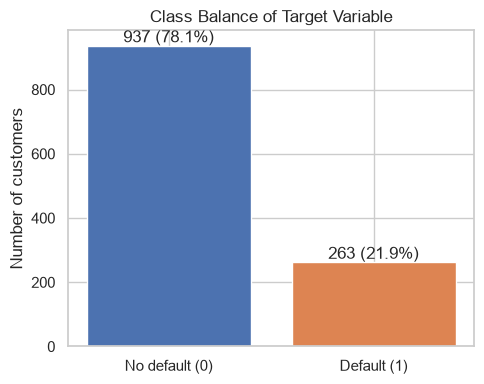

In [17]:
counts = df["default"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["No default (0)", "Default (1)"], counts.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, f"{v} ({v/len(df):.1%})", ha="center")
ax.set_title("Class Balance of Target Variable")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig(FIG_DIR + "class_balance.png", dpi=150)
plt.show()

**Observation:** The dataset has 1,200 records and 13 columns with no missing values
or duplicates. The target is moderately imbalanced (~22% default), so we will use a
stratified train/test split and focus on F1-score and ROC-AUC rather than accuracy alone.

## 2. Exploratory Data Analysis

### 2.1 Numerical feature distributions

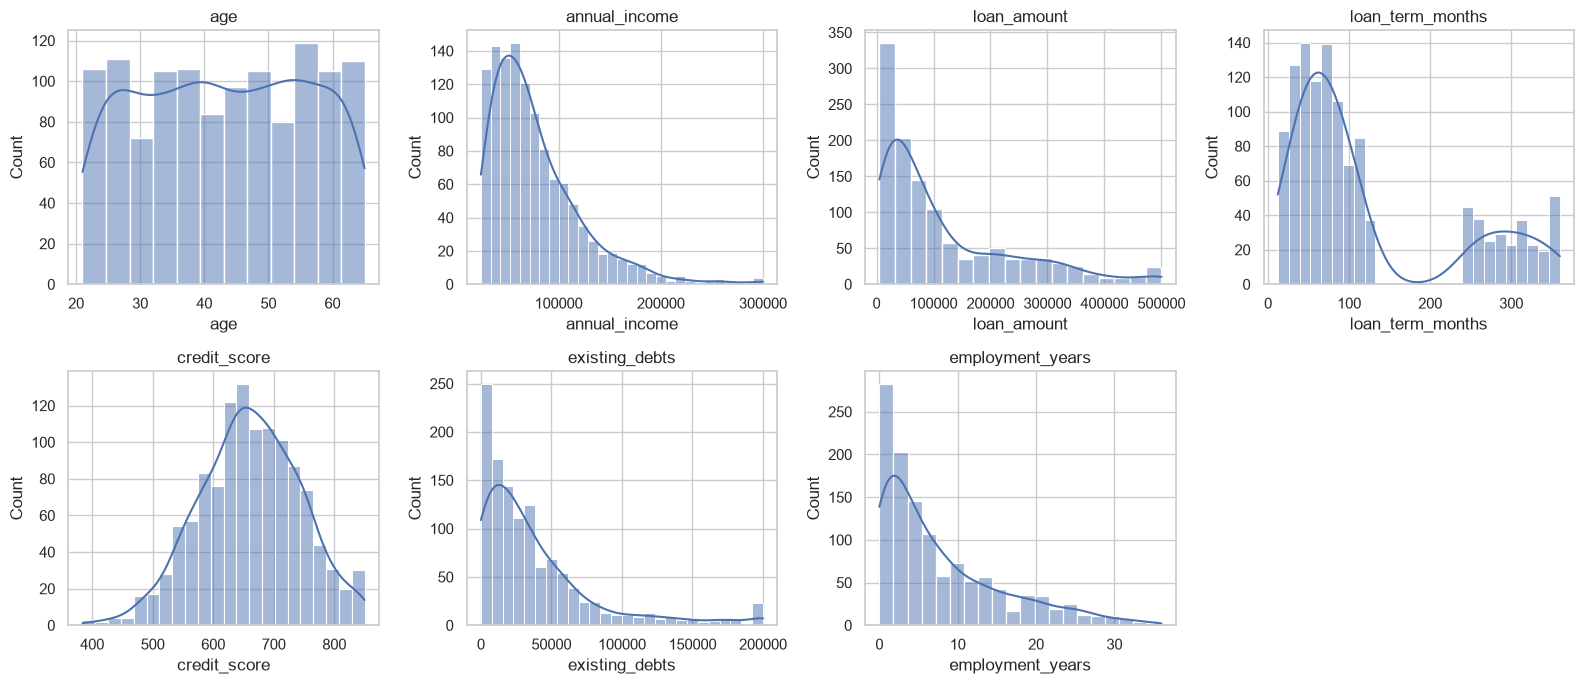

Skewness:
 age                -0.02
annual_income       1.64
loan_amount         1.37
loan_term_months    1.12
credit_score       -0.12
existing_debts      1.97
employment_years    1.25
dtype: float64


In [18]:
num_cols = ["age", "annual_income", "loan_amount", "loan_term_months",
            "credit_score", "existing_debts", "employment_years"]
cat_cols = ["employment_type", "region", "loan_purpose"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR + "numeric_distributions.png", dpi=150)
plt.show()

print("Skewness:\n", df[num_cols].skew().round(2))

**Observation:** `age` and `credit_score` are roughly symmetric, while `annual_income`,
`loan_amount`, `existing_debts`, `loan_term_months` and `employment_years` are
right-skewed (skewness 1.1–2.0). Scaling will be needed for distance/gradient-based
models (Logistic Regression, MLP, k-NN).

### 2.2 Numerical features by default status

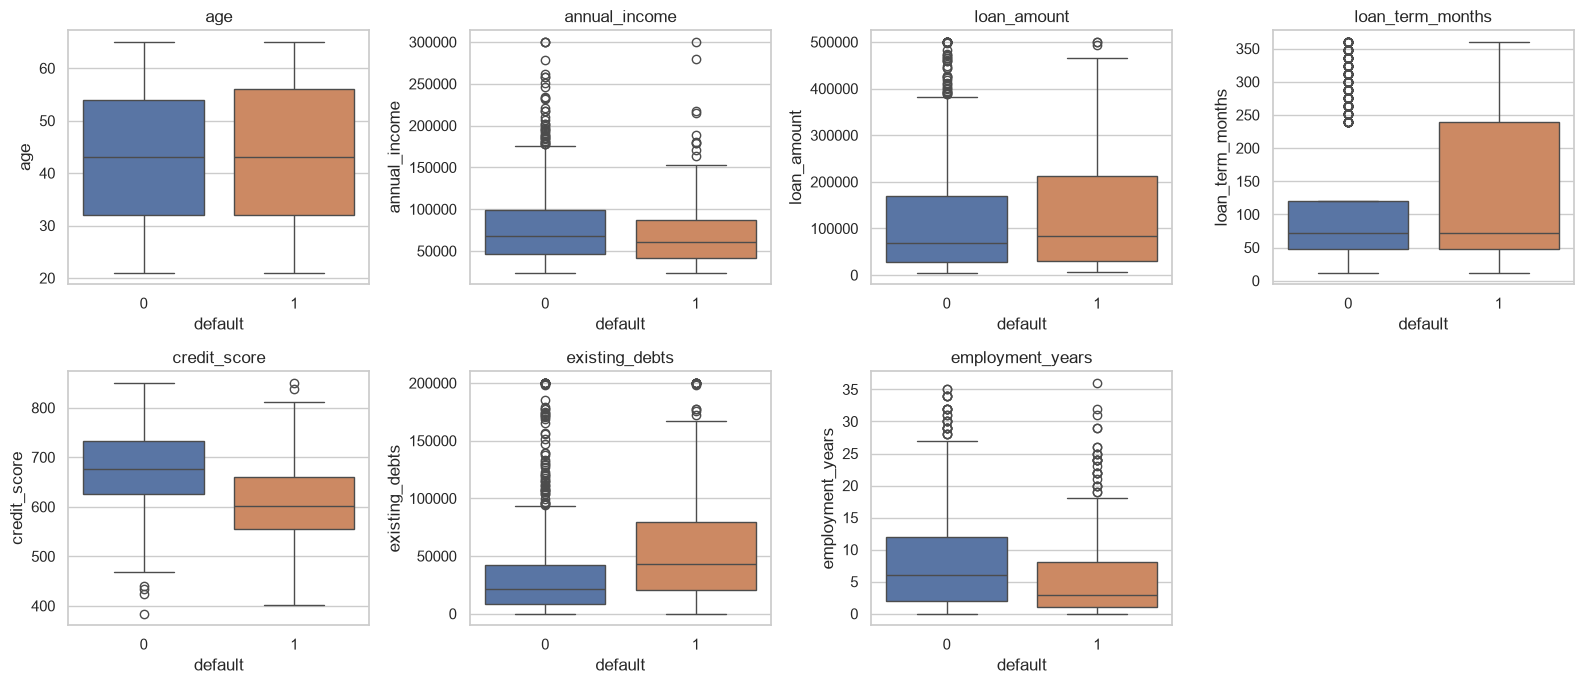

default,0,1
age,43.0,43.0
annual_income,67500.0,61000.0
loan_amount,68000.0,84500.0
loan_term_months,72.0,72.0
credit_score,677.0,601.0
existing_debts,21600.0,43300.0
employment_years,6.0,3.0


In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="default", y=col, hue="default", legend=False, ax=ax)
    ax.set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR + "boxplots_by_default.png", dpi=150)
plt.show()

df.groupby("default")[num_cols].median().T

**Observation:** Defaulters have a lower median credit score (601 vs 677), about double
the existing debts (RM43,300 vs RM21,600) and fewer years of employment (3 vs 6).
Age and loan term look almost identical between the two groups.

### 2.3 Correlation analysis

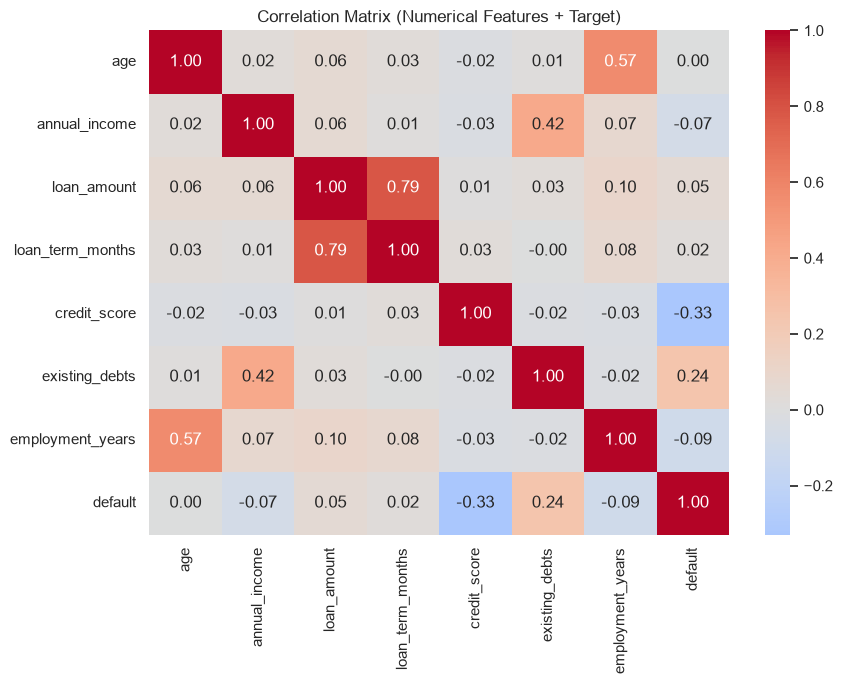

credit_score       -0.329681
employment_years   -0.094851
annual_income      -0.071448
age                 0.001294
loan_term_months    0.019655
loan_amount         0.049855
existing_debts      0.244925
Name: default, dtype: float64

In [26]:
corr = df[num_cols + ["default"]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix (Numerical Features + Target)")
plt.tight_layout()
plt.savefig(FIG_DIR + "correlation_heatmap.png", dpi=150)
plt.show()

corr["default"].drop("default").sort_values()

**Observation:** `credit_score` has the strongest relationship with default (r = −0.33),
followed by `existing_debts` (r = 0.25). Other features have weak linear correlation
(|r| < 0.1), but they may still matter in non-linear models or in combination.
No pair of features is highly correlated, so multicollinearity is not a concern.

### 2.4 Default rate by category

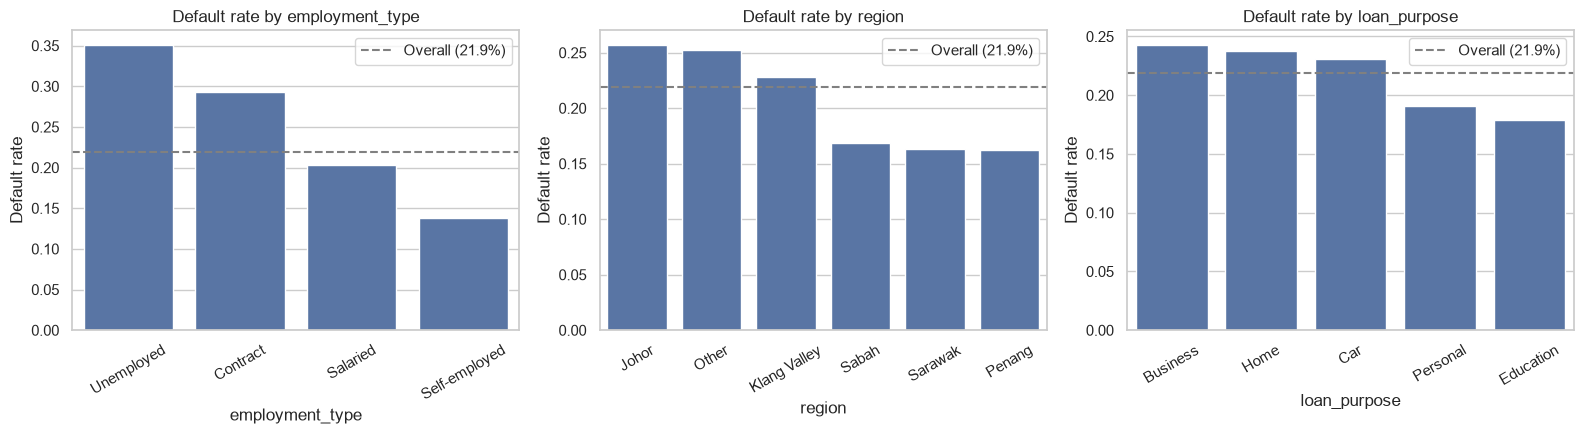

,rate,count
employment_type,,
Contract,0.293,225
Salaried,0.203,649
Self-employed,0.138,232
Unemployed,0.351,94


,rate,count
region,,
Johor,0.257,175
Klang Valley,0.228,482
Other,0.252,214
Penang,0.162,142
Sabah,0.168,95
Sarawak,0.163,92


,rate,count
loan_purpose,,
Business,0.243,177
Car,0.231,312
Education,0.179,106
Home,0.238,290
Personal,0.190,315


In [29]:
overall = df["default"].mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, cat_cols):
    rate = df.groupby(col)["default"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(overall, ls="--", color="grey", label=f"Overall ({overall:.1%})")
    ax.set_title(f"Default rate by {col}")
    ax.set_ylabel("Default rate")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + "default_rate_by_category.png", dpi=150)
plt.show()

for col in cat_cols:
    display(df.groupby(col)["default"].agg(rate="mean", count="size").round(3))

**Observation:** Employment type shows the clearest pattern: Unemployed (35.1%) and
Contract (29.3%) customers default far more than Salaried (20.3%) and Self-employed
(13.8%). Region and loan purpose vary less (16–26%), and smaller groups such as
Sabah and Sarawak (~90 records each) should be interpreted with caution.

### 2.5 Financial ratios

In [30]:
df["debt_to_income"] = df["existing_debts"] / df["annual_income"]
df["loan_to_income"] = df["loan_amount"] / df["annual_income"]

print(df.groupby("default")[["debt_to_income", "loan_to_income"]].median().round(2))
print("\nCorrelation with default:")
print(df[["debt_to_income", "loan_to_income", "default"]].corr()["default"].round(3))

         debt_to_income  loan_to_income
default                                
0                  0.34            0.98
1                  0.67            1.39

Correlation with default:
debt_to_income    0.379
loan_to_income    0.075
default           1.000
Name: default, dtype: float64


**Observation:** `debt_to_income` correlates with default more strongly (r = 0.38) than
any raw feature. The median for defaulters is about double that of non-defaulters
(0.67 vs 0.34).